In [1]:
from the_well.benchmark.metrics.spatial import VRMSE
import matplotlib.pyplot as plt
from einops import rearrange
import seaborn as sns
import pandas as pd
import numpy as np
import pickle
import torch
import math
import sys

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts}",
}

plt.rcParams.update(rc)

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

from waveletflux.utils.eval import build_stats_df, build_psd_df
from waveletflux.utils.plot import plot_psd, plot_psd_seaborn
#from waveletflux.utils.plot import plot_psd_seaborn
from waveletflux.utils.well_data import get_well_dataset

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# Get Dataset

In [2]:
well_base_path    = '/Users/gabrieleaccarino/Workspace/waveletflux/data/datasets'
well_dataset_name = 'rayleigh_benard'

outdir = f'{PROJECT_ROOT}/experiments/{well_dataset_name}/figures'

dataset = get_well_dataset(
    path=well_base_path,
    physics=well_dataset_name,
    split='test',
    steps=-1,          # loads full trajectory
    transform       = ['log_scalars'],   
    augment         = [],
)

meta_field_names = dataset.metadata.field_names
field_names = [item for sublist in meta_field_names.values() for item in sublist]

# Load predictions

In [3]:
RESULT_DIR = f"{PROJECT_ROOT}/experiments/{well_dataset_name}/results"

model_paths = {
    #"WaveletFM-1scale"          : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_1scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"WaveletFM-3scales"         : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_rollout_nsampling_steps20_nensemble1_traj.pkl',
    #"WaveletFM-3scales"         : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_v3.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "WaveletFM-3scales"     : f'{RESULT_DIR}/WaveletFlow_{well_dataset_name}_3scales_db2_v1.0_rollout_nsampling_steps20_nensemble1_traj.pkl',
    "UNetClassic"           : f'{RESULT_DIR}/UNetClassic_{well_dataset_name}_rollout_traj.pkl',
    "UNetConvNext"          : f'{RESULT_DIR}/UNetConvNext_{well_dataset_name}_rollout_traj.pkl',
}

generative_models = ["WaveletFM-1scale", "WaveletFM-3scales", "WaveletFM-3scales-last"]

# model data
rollout_traj = {}
for model, path in model_paths.items():
    with open(path, 'rb') as f:
        rollout_traj[model] = pickle.load(f)

# ground truth data
with open(f'{RESULT_DIR}/ground_truth_{well_dataset_name}_traj.pkl', 'rb') as f:
    truth_traj = pickle.load(f)

# Configuration

In [22]:
Ti = 4 # number of initial steps to skip (models start from these, so they are not predictions)

#lead_times = [1, 16, 32, 48, 64, 80, 96]

predictions = {
    #"WaveletFM-1scale"       : rollout_traj["WaveletFM-1scale"],   
    #"WaveletFM-3scales"      : rollout_traj["WaveletFM-3scales"],  
    "WaveletFM-3scales"      : rollout_traj["WaveletFM-3scales"],    
    "UNetClassic"            : rollout_traj["UNetClassic"],        
    "UNetConvNext"           : rollout_traj["UNetConvNext"],       
}

palette = sns.cubehelix_palette(len(predictions.keys()), start=2, dark=0.25)
#palette = sns.cubehelix_palette(len(table["model"].unique()), dark=0.25)
palette

[[0.8474590274530256, 0.8341308330637194, 0.9509595675385358],
 [0.4222025813968738, 0.5859841229046691, 0.6966196354229758],
 [0.11649760470158971, 0.31640224728208166, 0.26685137860728414]]

# Evaluation Metrics

In [5]:
aggregate_mode = "mean"

def horizon(t):
    if t <= 20:
        return "01:20"
    elif t <= 60:
        return "21:60"
    else:
        return "61:180"
    
def aggregate(x):
    if "mean" in aggregate_mode:
        return np.mean(x)
    elif "median" in aggregate_mode:
        return np.median(x)

def model_type(model):
    if model in generative_models:
        return "generative"
    return "deterministic"

# Build Stats DataFrame

In [6]:
df = build_stats_df(
    truth        = truth_traj,  
    predictions  = predictions,
    field_names  = field_names,
    Ti           = Ti,
    lead_times   = None,
    stride       = 1,
)

df["horizon"] = df["time"].apply(horizon)
df["model_type"] = df["model"].apply(model_type)

/opt/anaconda3/envs/diffusion_env/lib/python3.12/site-packages/ot/lp/solver_1d.py:46: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at /private/var/folders/k1/30mswbxs7r1g6zwn8y4fyt500000gp/T/abs_951ooclnw1/croot/libtorch_1746637517770/work/aten/src/ATen/native/TensorShape.cpp:3687.)
  idx = nx.searchsorted(cws, qs).T


In [7]:
df.columns

Index(['model', 'traj', 'field', 'step', 'time', 'm1', 'm2', 'spread', 'rmse',
       'nrmse', 'vrmse', 'spread_skill', 'total_error', 'w1', 'emd',
       'rmse_p_low', 'rmse_c_low', 'rmse_p_mid', 'rmse_c_mid', 'rmse_p_high',
       'rmse_c_high', 'rmse_p_vhigh', 'rmse_c_vhigh', 'horizon', 'model_type'],
      dtype='object')

In [8]:
summary = (
    df.groupby(["model", "field"])[["vrmse", "rmse_p_low", "rmse_p_mid", "rmse_p_high"]]
    .mean()
    .round(4)
)
print(summary.to_string())

                                vrmse    rmse_p_low  rmse_p_mid  rmse_p_high
model             field                                                     
UNetClassic       buoyancy     1.6223  1.600990e+01      1.3962       0.2857
                  pressure     1.4300  2.387000e+00      1.5511       1.6932
                  velocity_x  10.2471  1.908325e+06   2747.2845      20.8207
                  velocity_y   4.9298  9.159793e+04    374.0053       6.6342
UNetConvNext      buoyancy     1.3058  2.042900e+00      0.7718       0.2496
                  pressure     0.5659  7.672000e-01      0.9871       1.1837
                  velocity_x   2.6979  2.152205e+04    119.7548       3.2698
                  velocity_y   1.9912  5.712438e+03     41.4986       3.8772
WaveletFM-3scales buoyancy     0.6725  3.189000e-01      0.1226       0.1699
                  pressure     0.4147  2.643000e-01      0.2461       0.2243
                  velocity_x   2.3304  1.437689e+04     62.1366       1.5016

In [ ]:
#summary.style.apply(highlight_min_per_field_horizon, axis=None).format(precision=3)

# Plot: VRMSE at different rollout steps/regimes

In [9]:
field_names

['buoyancy', 'pressure', 'velocity_x', 'velocity_y']

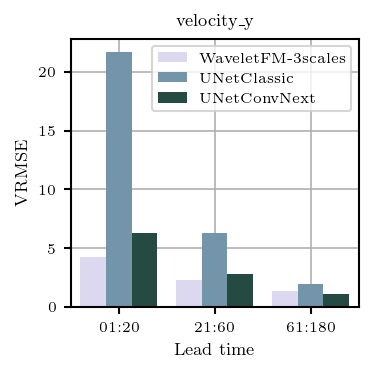

In [13]:
%matplotlib inline

#field = field_names
#table = df[df["field"].isin(field)]

field = 'velocity_y'
table = df[df["field"] == field]

fig = plt.figure(figsize=(2.4, 2.4))

ax = sns.barplot(
    table,
    x="horizon",
    y="vrmse",
    hue="model",
    estimator=aggregate,
    errorbar=None,
    palette=palette, #sns.cubehelix_palette(5, dark=0.25)[1:],
)

ax.grid()
ax.get_legend().set_title(None)

ax.set_xlabel("Lead time")
ax.set_ylabel("VRMSE")
ax.set_title(field)

fig.tight_layout(pad=0.33)

plt.savefig(f"{outdir}/vrmse_rollout_{field}.png", dpi=300, transparent=True)
plt.show()

# Plot: Averaged Power Spectrum RMSE across test trajectories

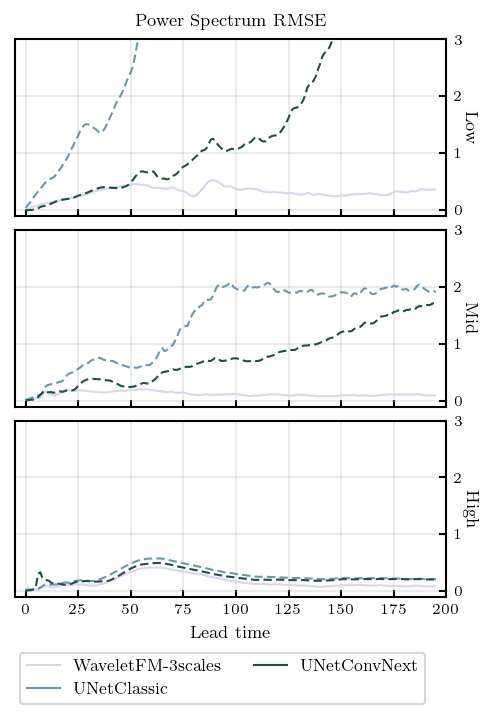

In [27]:
%matplotlib inline

field = 'buoyancy'
table = df[df['field'] == field]

fig, axs = plt.subplot_mosaic(
    [[0], [1], [2]],
    figsize=(3.2, 4.8),
    sharex=True,
    sharey=False,
)

# solid for generative, dashed for deterministic
dashes  = {"generative": (1, 0), "deterministic": (4, 2)}

for i, band in enumerate(["Low", "Mid", "High"]):
    ax = sns.lineplot(
        table,
        x="time",
        y=f"rmse_p_{band.lower()}",
        hue="model",
        style="model_type",
        dashes=dashes,
        estimator=aggregate,
        errorbar=None,
        palette=palette,
        ax=axs[i],
    )
    ax.grid(alpha=0.3)

    ax.set_xlabel("Lead time" if i == 2 else "")
    ax.set_xlim(-5, 200)

    ax.set_ylabel(band)
    ax.set_ylim(-0.1, 3.0)

    ax.tick_params(direction="in")
    ax.yaxis.set_label_position("right")
    ax.yaxis.label.set(rotation=-90, va="center")
    ax.yaxis.tick_right()

    if i == 0:
        ax.set_title("Power Spectrum RMSE")
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()

# ── Clean up legend: remove the "model_type" section header ───────────────────
clean = [(h, l) for h, l in zip(handles, labels) if l not in ("model_type", "generative", "deterministic", "model")]
handles_clean, labels_clean = zip(*clean)

fig.align_labels()
fig.tight_layout(pad=0.33)
fig.subplots_adjust(bottom=0.18)  # make room at the bottom
fig.legend(handles_clean, labels_clean, loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.45, 0.02))
plt.show()

# Plot PSD

In [18]:
psd_df = build_psd_df(
    truth = truth_traj,
    predictions = predictions,
    field_names = field_names,
    Ti = Ti,
    lead_times = None,
    stride = 1,      
    min_bin_count = 3,   
)

In [19]:
psd_df

,model,traj,ens,field,step,time,k,wavelength,band,psd
0,Ground-truth,0,0,buoyancy,0,0,0.007857,127.279228,low,3.786480e+01
1,Ground-truth,0,0,buoyancy,0,0,0.015713,63.639614,low,4.974473e+00
2,Ground-truth,0,0,buoyancy,0,0,0.023570,42.426411,low,2.011643e+00
3,Ground-truth,0,0,buoyancy,0,0,0.031427,31.819807,mid,1.545304e+00
4,Ground-truth,0,0,buoyancy,0,0,0.039284,25.455845,mid,9.454718e-01
...,...,...,...,...,...,...,...,...,...,...
2540155,UNetConvNext,8,0,velocity_y,195,195,0.675680,1.479991,vhigh,1.972999e-08
2540156,UNetConvNext,8,0,velocity_y,195,195,0.683537,1.462980,vhigh,2.215505e-08
2540157,UNetConvNext,8,0,velocity_y,195,195,0.691393,1.446355,vhigh,3.046241e-08
2540158,UNetConvNext,8,0,velocity_y,195,195,0.699250,1.430104,vhigh,8.424050e-08


# Plot PSD per field

- https://github.com/francois-rozet/lola/blob/main/lola/plot.py

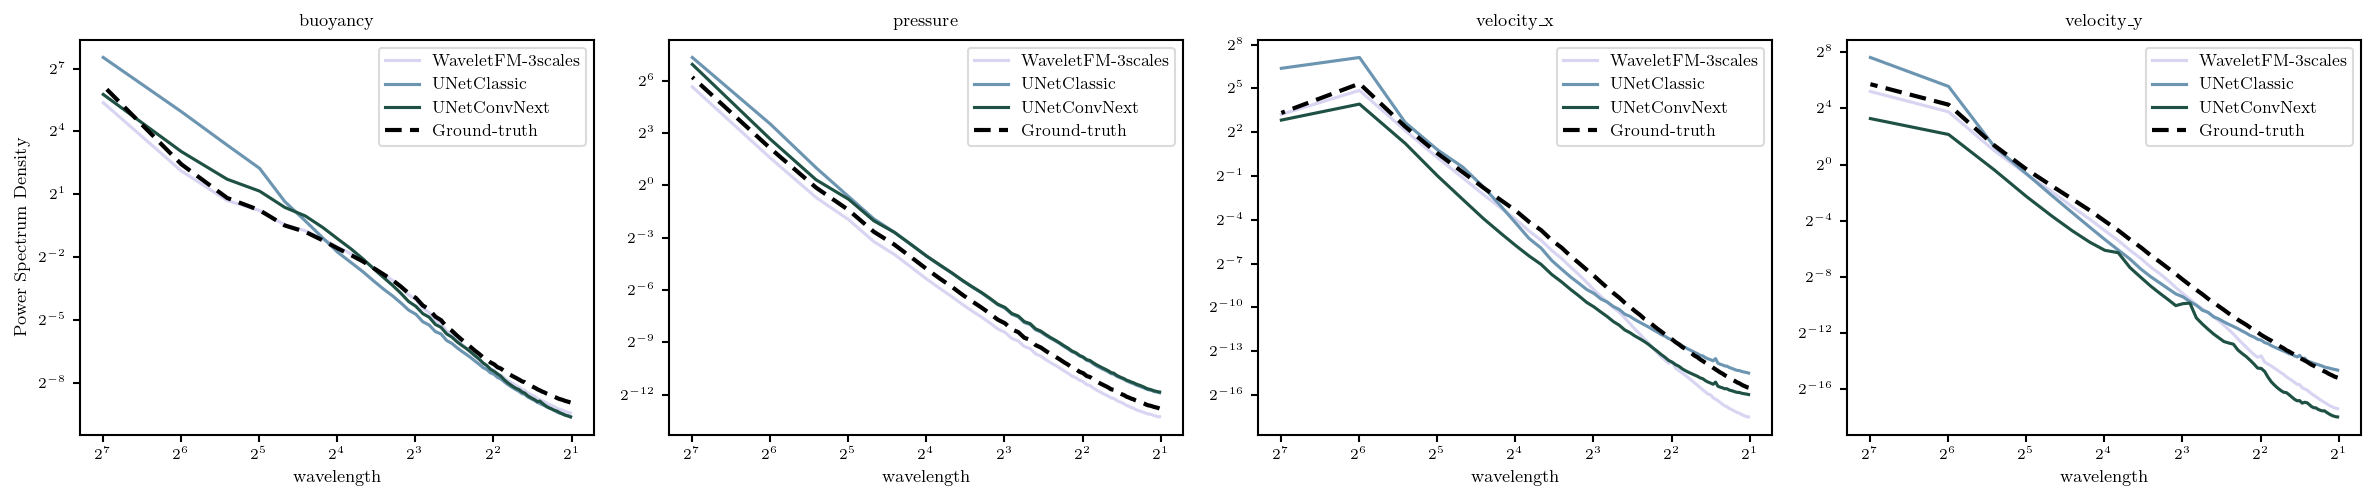

In [23]:
import math
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

#field_names = psd_df["field"].unique().tolist()
#field_names = ['density', 'pressure', '']
gt_label    = "Ground-truth"
all_models  = [m for m in psd_df["model"].unique() if m != gt_label]
#palette     = dict(zip(all_models, sns.color_palette("tab10", n_colors=len(all_models))))
wl_min, wl_max = 1, 128


fig, axs = plt.subplots(
    1, len(field_names),
    figsize=(4.0 * len(field_names), 3.5),
    sharey=False,
    squeeze=False,
)

for col_idx, field in enumerate(field_names):
    ax = axs[0, col_idx]
    df_field = psd_df[(psd_df["field"] == field) & 
                      (psd_df["band"] != "vhigh") &
                      (psd_df["wavelength"] >= wl_min) & 
                      (psd_df["wavelength"] <= wl_max)]

    # ── non-GT models ──────────────────────────────────────────────────────────
    sns.lineplot(
        data=df_field[(df_field["model"] != gt_label)],
        x="wavelength",
        y="psd",
        hue="model",
        palette=palette,
        estimator="mean",
        errorbar=None, #("ci", 95),
        linewidth=1.5,
        ax=ax,
    )

    # ── ground truth — black dashed, no CI ────────────────────────────────────
    sns.lineplot(
        data=df_field[(df_field["model"] == gt_label)],
        x="wavelength",
        y="psd",
        color="black",
        dashes=(4, 2),
        estimator="mean",
        errorbar=None,
        linewidth=2.0,
        label=gt_label,
        ax=ax,
    )

    # ── axes: log-log, then invert x (axes-level → invert_xaxis sticks) ───────
    ax.set_xscale("log", base=2)
    ax.set_yscale("log", base=2)
    ax.invert_xaxis()   # large wavelength (low k) on the left

    # ── ticks as 2^n ──────────────────────────────────────────────────────────
    wl      = df_field["wavelength"].replace([np.inf], np.nan).dropna()
    exp_min = math.floor(math.log2(wl.min()))
    exp_max = math.ceil(math.log2(wl.max()))
    ticks   = [2 ** e for e in range(exp_min, exp_max + 1)]
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(
        ticker.FuncFormatter(lambda v, _: rf"$2^{{{int(round(math.log2(v)))}}}$" if v > 0 else "")
    )
    ax.xaxis.set_minor_locator(ticker.NullLocator())

    ax.set_title(field)
    ax.set_xlabel("wavelength")
    ax.set_ylabel("Power Spectrum Density" if col_idx == 0 else "")

    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, fontsize=8, framealpha=0.7)

fig.tight_layout()
plt.show()

In [ ]:
fig = plot_psd_seaborn(
    psd_df=psd_df,
    field_names=field_names,
    agg_over=["traj", "ens", "step"],
    gt_label="Ground-truth",
    palette=palette,
    gt_color="black",
    gt_lw=1.5,
    model_lw=1.0,
    ci=None,
    figsize=(4.0, 3.5),
    log_base=2,
)

# PSD Plot from LOLA (select traj + ens + specific step in the trajectory)

In [ ]:
truth_traj.shape

In [ ]:
TRAJ_IDX = 5

x = truth_traj[TRAJ_IDX, ...]
x = rearrange(x, "steps h w c -> c steps h w")
y = predictions['WaveletFM-3scales'][TRAJ_IDX, 0, ...]
#y = predictions['WaveletFM-1scale'][TRAJ_IDX, 0, ...]
#y = predictions['UNetClassic'][TRAJ_IDX, ...]
y = rearrange(y, "steps h w c -> c steps h w")

print(x.shape, y.shape)


plot_psd(
    x = x[:, 64],
    y = y[:, 64],
    fields = field_names,  
)

# Tables 

In [ ]:
table = df[["model", "field", "horizon", "vrmse"]]

table = table.groupby(["model", "field", "horizon"]).agg(aggregate).round(3).reset_index()
table = table.pivot(index=["model", "field"], columns="horizon", values=["vrmse"])
# print(table.to_latex(float_format="%.3f"))
table

In [ ]:
import pandas as pd

def highlight_min_per_field_horizon(df: pd.DataFrame) -> pd.DataFrame:
    styles = pd.DataFrame("", index=df.index, columns=df.columns)

    fields = df.index.get_level_values("field").unique()

    for field, color in zip(fields, palette):
        r, g, b = [int(c * 255) for c in color[:3]]
        css = f"background-color: rgb({r},{g},{b}); color: white; font-weight: bold"

        field_mask = df.index.get_level_values("field") == field
        sub = df.loc[field_mask]           # rows for this field, all models

        for col in df.columns:
            min_idx = sub[col].idxmin()    # (model, field) index of the min
            styles.loc[min_idx, col] = css

    return styles

In [ ]:
table.style.apply(highlight_min_per_field_horizon, axis=None).format(precision=3)